# 17 — InBody OCR: PP-OCRv6 + spatial field association

So sánh 2×2 trên dữ liệu **giả lập**: v5/v6 và gom hàng/ghép trường theo bố cục.
Không phải đánh giá độ chính xác phiếu InBody thật. Không gọi model hoặc tải dữ liệu khi mở notebook.
Chạy trước: `.venv-ocr/Scripts/python.exe scripts/prepare_inbody_layout_synthetic.py`, rồi
`.venv-ocr/Scripts/python.exe scripts/compare_inbody_ocr.py`.

In [1]:
from pathlib import Path
import json, hashlib
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "configs").exists(): ROOT = ROOT.parent
report = json.loads((ROOT / "experiments/inbody_ocr_comparison_v1/metrics.json").read_text(encoding="utf-8"))
manifest_path = ROOT / "data/manifests/inbody_layout_synthetic_v1.json"
assert report["manifest_sha256"] == hashlib.sha256(manifest_path.read_bytes()).hexdigest()
assert report["synthetic_only"] and report["real_documents"] == 0 and not report["release_approved"]
print(report["design"])
print(report["package_versions"])
display(Markdown((ROOT / "experiments/inbody_ocr_comparison_v1/report.md").read_text(encoding="utf-8")))

Each model infers once per input; both associations consume identical tokens. No template/annotation routing.
{'paddleocr': '3.7.0', 'paddlepaddle': '3.3.1', 'paddlex': '3.7.2', 'Pillow': '12.3.0'}


# PP-OCRv5/v6 and spatial association comparison

**Synthetic engineering regression only. Real report accuracy is unknown.**

Documents: 16; real documents: 0. Each OCR model ran once per input; rows/layout use the same tokens.

| Pipeline | Field precision | Field recall | Field F1 | Whole document exact | Date exact | Mean seconds |
|---|---:|---:|---:|---:|---:|---:|
| v5_rows | 1.0000 | 0.5071 | 0.6730 | 0.5000 | 1.0000 | 5.567 |
| v5_layout | 1.0000 | 0.8214 | 0.9020 | 0.5000 | 1.0000 | 5.571 |
| v6_rows | 1.0000 | 0.5071 | 0.6730 | 0.5000 | 1.0000 | 20.110 |
| v6_layout | 1.0000 | 0.6714 | 0.8034 | 0.5000 | 1.0000 | 20.113 |

V6 + layout is the configured primary research candidate, not an automatic production promotion.
Field exactness includes missing/extra/wrong values; null/null contributes no field true positive.
Spatial recall is available only for layout variants on new fixtures with annotated value cells.
Per-field unit-specific MAE, language/layout groups, OCR CER/WER and error lists are in metrics.json.

## Limits
- Original synthetic regression fixtures, already inspectable; not an untouched real-world test set
- CER/WER are computed on raw full-page OCR, not canonical field lines
- OCR scores are not calibrated field correctness probabilities
- No human correction-rate study, real InBody report, external layout or phone-capture benchmark
- CPU timings exclude startup and model downloads


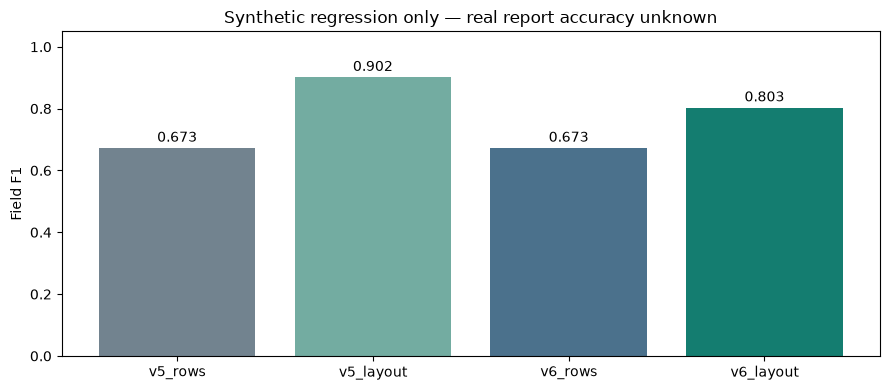

In [2]:
import matplotlib.pyplot as plt
names = list(report["results"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(names, [report["results"][key]["field_f1"] for key in names], color=["#72838f", "#73aca1", "#4b718c", "#147d70"])
ax.set(ylim=(0, 1.05), ylabel="Field F1", title="Synthetic regression only — real report accuracy unknown")
for i, key in enumerate(names): ax.text(i, report["results"][key]["field_f1"] + .02, f'{report["results"][key]["field_f1"]:.3f}', ha="center")
fig.tight_layout()
fig.savefig(ROOT / "experiments/inbody_ocr_comparison_v1/field_f1.png", dpi=150)
plt.show()

Các đường bao dưới đây là bằng chứng OCR/ghép trường, không phải xác nhận rằng số đã đọc đúng.
Một nhãn có nhiều số không xác định được cột phải để trống hoặc chọn template đã kiểm chứng bằng tay.

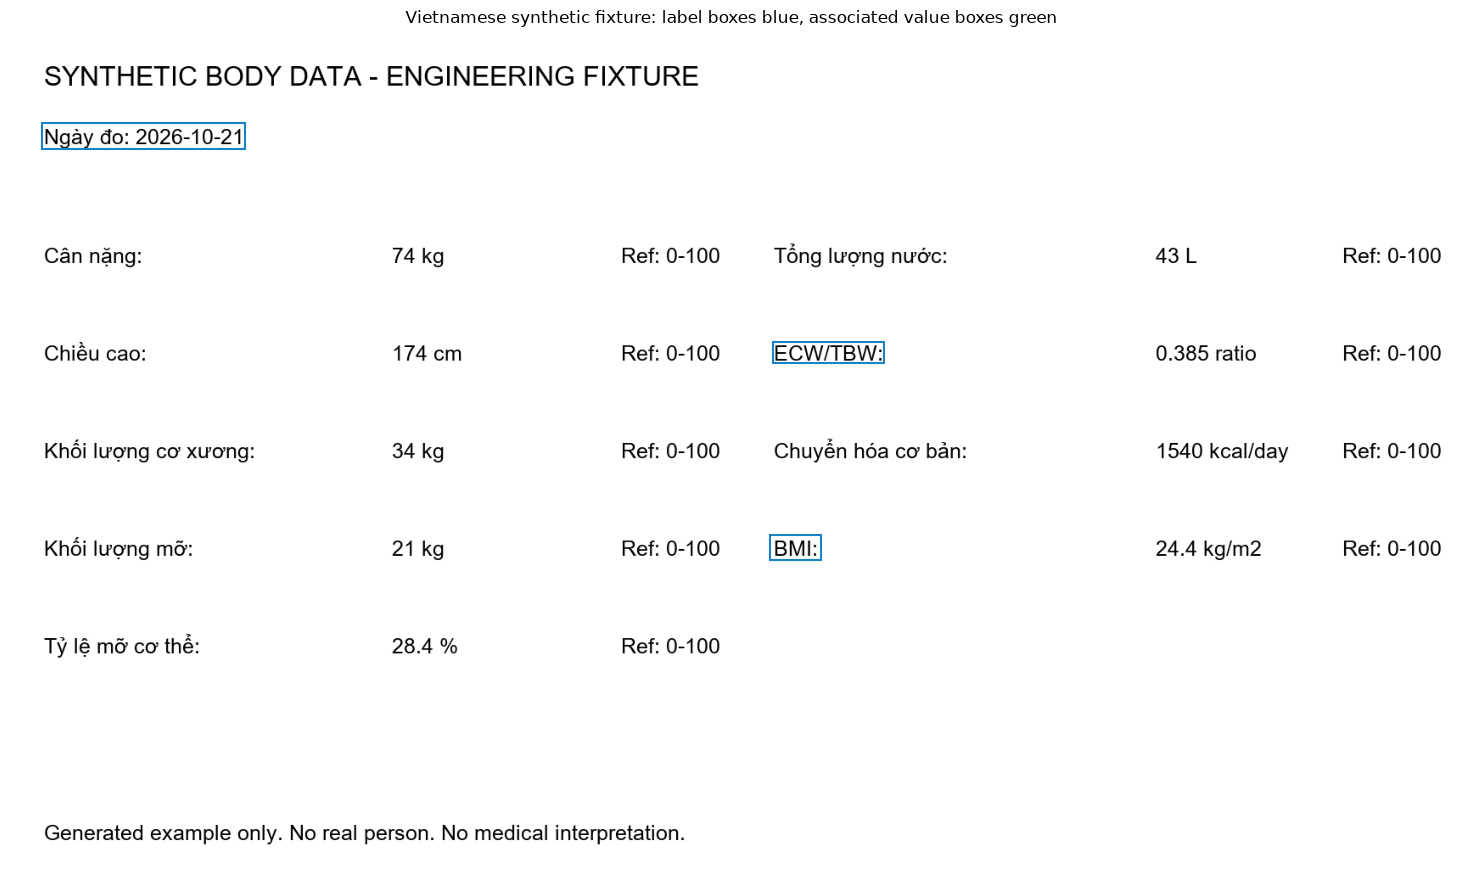

In [3]:
from PIL import Image, ImageOps
from matplotlib.patches import Rectangle
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
sample = next(sample for sample in manifest["samples"] if sample["document_id"] == "layout-synthetic-004")
layout = json.loads((ROOT / "data/processed/inbody_ocr_comparison_v1/v6" / sample["document_id"] / "layout.json").read_text(encoding="utf-8"))
fig, ax = plt.subplots(figsize=(16, 9))
with Image.open(ROOT / sample["image"]) as image: ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
for entry in layout["entries"]:
    for role, color in (("label_box", "#1984c5"), ("value_box", "#15976a")):
        box = entry[role]
        if box: ax.add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, edgecolor=color, linewidth=1.5))
ax.set_title("Vietnamese synthetic fixture: label boxes blue, associated value boxes green")
ax.axis("off")
fig.tight_layout()
fig.savefig(ROOT / "experiments/inbody_ocr_comparison_v1/spatial_evidence.png", dpi=140)
plt.show()

In [4]:
selected = report["results"]["v6_layout"]
print("Per-field normalized numeric errors:")
for field, metrics in selected["per_field"].items():
    print(field, {key: metrics[key] for key in ("unit", "labeled", "predicted", "exact", "coverage", "mae")})
print("First errors:", selected["errors"][:12])
print("Human correction rate:", report["correction_rate"])
print("Limitations:", report["limitations"])

Per-field normalized numeric errors:
weight_kg {'unit': 'kg', 'labeled': 15, 'predicted': 8, 'exact': 8, 'coverage': 0.5333333333333333, 'mae': 0.0}
height_cm {'unit': 'cm', 'labeled': 16, 'predicted': 9, 'exact': 9, 'coverage': 0.5625, 'mae': 0.0}
skeletal_muscle_mass_kg {'unit': 'kg', 'labeled': 16, 'predicted': 13, 'exact': 13, 'coverage': 0.8125, 'mae': 0.0}
body_fat_mass_kg {'unit': 'kg', 'labeled': 16, 'predicted': 12, 'exact': 12, 'coverage': 0.75, 'mae': 0.0}
percent_body_fat {'unit': '%', 'labeled': 16, 'predicted': 12, 'exact': 12, 'coverage': 0.75, 'mae': 0.0}
total_body_water_l {'unit': 'L', 'labeled': 13, 'predicted': 8, 'exact': 8, 'coverage': 0.6153846153846154, 'mae': 0.0}
ecw_tbw_ratio {'unit': 'ratio', 'labeled': 16, 'predicted': 8, 'exact': 8, 'coverage': 0.5, 'mae': 0.0}
basal_metabolic_rate_kcal {'unit': 'kcal/day', 'labeled': 16, 'predicted': 12, 'exact': 12, 'coverage': 0.75, 'mae': 0.0}
bmi {'unit': 'kg/m2', 'labeled': 16, 'predicted': 12, 'exact': 12, 'coverage

## Bước tiếp theo

Thu thập phiếu thật được phép sử dụng; gán nhãn giá trị, ngày đo, đơn vị và bbox kết quả/tham chiếu.
Chia theo người/phiếu gốc và holdout nguồn/layout. So sánh exact fields, bỏ sót/số sai, date/unit accuracy,
coverage và thời gian sửa từ người đối chiếu. Chưa mở OCR trong ứng dụng production dựa trên tập giả lập này.